# v34 per-trajectory ランカー — 576本のどれを信用するかを軌跡単位で学習
ユーザー仮説: 過去の選択失敗(v18/v20)はデータの粒度不足。per-seed dump がある今なら可能。

**v20 との違い(死因への対処)**:
1. ラベル = best当て(argmax=ノイズ)ではなく **各軌跡の誤差 median|traj−true| を井戸内z正規化した連続値**
2. 特徴 = GR尤度系だけでなく **メタデータ(src/param/sm-fw/ww)+軌跡単体のクロスGR採点+物理(荒れ/dip/jump)+モード文脈**
3. 出力 = hard選択でなく **softmax(−q̂·β) 重みの加重平均軌跡**(n本選んで平均、の学習版)
4. サンプル = 井戸×576 ≈ 33万行(v20 は井戸×7本)

**判定(撤退ライン付き)**:
- 学習ゲート: OOF の井戸内 Spearman(予測順位 vs 実誤差順位)
- 集約ゲート: **加重平均軌跡の overall が「等重みコンセンサス」と「ww(尤度)加重平均」の両方に勝つか**。
  勝てなければ撤退(oracle は参考値)。勝てば「学習済み集約PF軌跡」として v35 の特徴列に還流。


In [1]:
# ===== ロード: 真値 + per-seed dump =====
import json, warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
warnings.filterwarnings("ignore")
matplotlib.rcParams["font.family"] = "Meiryo"; matplotlib.rcParams["axes.unicode_minus"] = False

PROJECT = Path(r"C:\Users\kosaka256\Documents\rogii_claude")
V28_ART = PROJECT / "v28" / "artifacts_v28"
V32_ART = PROJECT / "v32" / "artifacts_v32"
ART = PROJECT / "v34" / "artifacts_v34"

tbl = pq.read_table(V28_ART / "data" / "train.parquet",
                    columns=["well", "target", "last_known_tvt", "md_since",
                             "pf_nbr_has", "pf_nbr_nrefs", "pf_nbr_nndist"])
g = tbl.column("well").to_pandas().to_numpy()
y0 = tbl.column("target").to_numpy(zero_copy_only=False).astype(np.float64)
lk = tbl.column("last_known_tvt").to_numpy(zero_copy_only=False).astype(np.float64)
mds = tbl.column("md_since").to_numpy(zero_copy_only=False).astype(np.float64)
has = tbl.column("pf_nbr_has").to_numpy(zero_copy_only=False).astype(np.float64)
nrefs_c = tbl.column("pf_nbr_nrefs").to_numpy(zero_copy_only=False).astype(np.float64)
nnd_c = tbl.column("pf_nbr_nndist").to_numpy(zero_copy_only=False).astype(np.float64)
tvt_true = lk + y0
wid = list(pd.unique(g))
rows_of = {w: np.where(g == w)[0] for w in wid}
HARD = set(pd.read_csv(V32_ART / "hardcore_diag.csv", index_col=0).query(
    "rmse_prior >= 10 and abs(bias) > 8").index) & set(wid)
DUMPS = {k: np.load(ART / f"seed_dump_pf{k}.npz") for k in (1, 2, 3)}
KEYS = {k: set(DUMPS[k].files) for k in (1, 2, 3)}
def rmse(e):
    e = e[np.isfinite(e)]
    return float(np.sqrt(np.mean(e ** 2))) if e.size else np.nan
print(f"wells {len(wid)} | 硬い核 {len(HARD)}")


wells 773 | 硬い核 27


In [2]:
# ===== 軌跡テーブル生成(1行=1軌跡, ~33万行)。artifacts_v34/traj_table.parquet に保存(再利用) =====
GAP_LINK = 8.0
SRCS = ("tw", "self", "nbr"); FLTS = (("sm", "ps"), ("fw", "pfw"))

def score_batch(TR, gg, gmin, gst, gs, gr):
    """TR (S,T) を grid で一括採点(行ごとの GR一致度平均)。"""
    G = len(gg)
    ii = np.clip((TR - gmin) / gst, 0.0, G - 1.000001)
    i0 = ii.astype(int); t = ii - i0
    eg = gg[i0] * (1 - t) + gg[np.minimum(i0 + 1, G - 1)] * t
    m = np.isfinite(gr)[None, :] & np.isfinite(eg)
    d = np.where(m, (gr[None, :] - eg) / gs, np.nan)
    with np.errstate(all="ignore"):
        return np.nanmean(np.exp(-0.5 * d * d), axis=1)

def cluster(ds, wts):
    o = np.argsort(ds)
    groups, cur = [], [o[0]]
    for i in o[1:]:
        if ds[i] - ds[cur[-1]] > GAP_LINK: groups.append(cur); cur = [i]
        else: cur.append(i)
    groups.append(cur)
    lab = np.empty(len(ds), int); minfo = []
    for mi, m in enumerate(groups):
        m = np.array(m); lab[m] = mi
        minfo.append(dict(mass=float(wts[m].sum()), idx=m))
    return lab, minfo

t0 = time.time(); rows = []
TRAJ = {}   # w -> (ALL, T, item_meta)  … 集約評価(セル4)で再利用
for iw, w in enumerate(wid):
    r = rows_of[w]
    nbr_ok = np.nanmean(has[r]) > 0.5
    trajs, wts, meta_run = [], [], []
    for k in (1, 2, 3):
        z = DUMPS[k]
        for src in SRCS:
            if src == "nbr" and not nbr_ok: continue
            if f"{w}|ps_{src}" not in KEYS[k]: continue
            ww_ = z[f"{w}|ww_{src}"]; ll_ = z[f"{w}|ll_{src}"]
            for flt, pref in FLTS:
                trajs.append(z[f"{w}|{pref}_{src}"]); wts.append(ww_)
                meta_run.append((k, src, flt, ll_))
    if not trajs: continue
    n_runs = len(trajs)
    T = min(min(t_.shape[1] for t_ in trajs), len(r))
    if T < 5: continue
    ALL = np.concatenate([t_[:, :T].astype(np.float64) for t_ in trajs], 0)
    IW = np.concatenate([wv / n_runs for wv in wts])
    cons = np.median(ALL, axis=0)
    ds = np.nanmedian(ALL - cons[None, :], axis=1)
    fin = np.isfinite(ds)
    lab, minfo = cluster(np.where(fin, ds, 0.0), IW)   # 非有限は中央扱い(後で除外)
    tot_mass = max(IW.sum(), 1e-12)
    top_mi = int(np.argmax([m["mass"] for m in minfo]))
    # モードごとの ext(=self/nbr run)質量
    run_src = []
    for (k, src, flt, ll_), t_ in zip(meta_run, trajs):
        run_src += [src] * t_.shape[0]
    run_src = np.array(run_src)
    ext_mass_of = {mi: float(IW[(lab == mi) & np.isin(run_src, ("self", "nbr"))].sum())
                   for mi in range(len(minfo))}
    # 物理系(バッチ)
    z1 = DUMPS[1]
    md_ = z1[f"{w}|md"].astype(np.float64)[:T]; zz = z1[f"{w}|z"].astype(np.float64)[:T]
    ir = float(z1[f"{w}|ir"])
    dmd = np.maximum(np.diff(md_), 1.0)
    GT = np.diff(ALL + zz[None, :], axis=1) / dmd[None, :]
    dip_med = np.nanmedian(GT, axis=1); dip_mx = np.nanpercentile(np.abs(GT), 95, axis=1)
    jump = np.nanmax(np.abs(np.diff(ALL + zz[None, :], axis=1)), axis=1)
    r2 = np.nanmean(np.abs(np.diff(ALL, 2, axis=1)), axis=1)
    b2 = float(np.nanmean(np.abs(np.diff(cons, 2)))) + 1e-6
    # クロス採点(run の param の grid で採点、cons とのマージン)
    xsc = {"tw": np.full(len(ALL), np.nan), "self": np.full(len(ALL), np.nan), "nbr": np.full(len(ALL), np.nan)}
    pos = 0
    for (k, src, flt, ll_), t_ in zip(meta_run, trajs):
        S = t_.shape[0]; sl = slice(pos, pos + S); pos += S
        z = DUMPS[k]
        gmin, gst, gs = z[f"{w}|meta"]; gr = z[f"{w}|gr"].astype(np.float64)[:T]
        for nmk, gk in [("tw", "gg_tw"), ("self", "gg_self"), ("nbr", "gg_nbr")]:
            if f"{w}|{gk}" not in KEYS[k]: continue
            gg = z[f"{w}|{gk}"].astype(np.float64)
            sc = score_batch(ALL[sl], gg, gmin, gst, gs, gr)
            s0 = score_batch(cons[None, :], gg, gmin, gst, gs, gr)[0]
            xsc[nmk][sl] = sc - s0
    # sm↔fw 乖離(同じ run ペア)
    smfw = np.full(len(ALL), np.nan); pos = 0
    offs = np.cumsum([0] + [t_.shape[0] for t_ in trajs])
    for i_run, (k, src, flt, ll_) in enumerate(meta_run):
        j_run = i_run + 1 if flt == "sm" else i_run - 1   # (sm,fw) が隣接して並ぶ生成順
        if 0 <= j_run < n_runs and meta_run[j_run][1] == src and meta_run[j_run][0] == k:
            a = ALL[offs[i_run]:offs[i_run + 1]]; b = ALL[offs[j_run]:offs[j_run + 1]]
            smfw[offs[i_run]:offs[i_run + 1]] = np.nanmean(np.abs(a - b), axis=1)
    # ラベル: 各軌跡の誤差(median|traj−true|)と 井戸内z
    err = np.nanmedian(np.abs(ALL - tvt_true[r[:T]][None, :]), axis=1)
    ez = (err - np.nanmean(err)) / (np.nanstd(err) + 1e-9)
    md_len = float(np.nanmax(mds[r])) if np.isfinite(mds[r]).any() else np.nan
    pos = 0
    for i_run, ((k, src, flt, ll_), wv, t_) in enumerate(zip(meta_run, wts, trajs)):
        S = t_.shape[0]
        llz = (ll_ - np.nanmean(ll_)) / (np.nanstd(ll_) + 1e-9)
        wrank = np.argsort(np.argsort(-wv)) / max(S - 1, 1)
        for s in range(S):
            i = pos + s
            if not fin[i]: continue
            rows.append(dict(
                well=w, err=float(err[i]), y=float(ez[i]),
                src_tw=int(src == "tw"), src_self=int(src == "self"), src_nbr=int(src == "nbr"),
                pset=k, flt_sm=int(flt == "sm"),
                ww=float(wv[s]), ww_rank=float(wrank[s]), ll_z=float(llz[s]),
                d=float(ds[i]), d_abs=float(abs(ds[i])),
                mode_mass=float(minfo[lab[i]]["mass"] / tot_mass),
                mode_is_top=int(lab[i] == top_mi),
                mode_ext_mass=float(ext_mass_of[lab[i]] / tot_mass),
                x_tw=float(xsc["tw"][i]), x_self=float(xsc["self"][i]), x_nbr=float(xsc["nbr"][i]),
                dip_dev=float(abs(dip_med[i] - ir)), dip_absmax=float(dip_mx[i]),
                geo_jump=float(jump[i]), rough_ratio=float(r2[i] / b2),
                smfw_gap=float(smfw[i]),
                seed_disp=float(np.nanstd(ds[fin])),
                nbr_ok=int(nbr_ok), nndist=float(np.nanmedian(nnd_c[r])),
                nrefs=float(np.nanmedian(nrefs_c[r])), n_rows=float(len(r)), md_len=md_len))
        pos += S
    TRAJ[w] = (ALL.astype(np.float32), T, err.astype(np.float32))
    if (iw + 1) % 100 == 0:
        print(f"  {iw+1}/{len(wid)} wells ({time.time()-t0:.0f}s)")
TT = pd.DataFrame(rows)
TT.to_parquet(ART / "traj_table.parquet", index=False)
print(f"traj_table: {len(TT)}行 / {TT['well'].nunique()}井戸  ({time.time()-t0:.0f}s) → 保存済")


  100/773 wells (47s)
  200/773 wells (91s)
  300/773 wells (136s)
  400/773 wells (183s)
  500/773 wells (227s)
  600/773 wells (274s)
  700/773 wells (320s)
traj_table: 408768行 / 773井戸  (353s) → 保存済


井戸内 Spearman(q̂ vs 実誤差): median 0.654 / mean 0.536 / 正 89%(0.3超なら順位はかなり学べている)


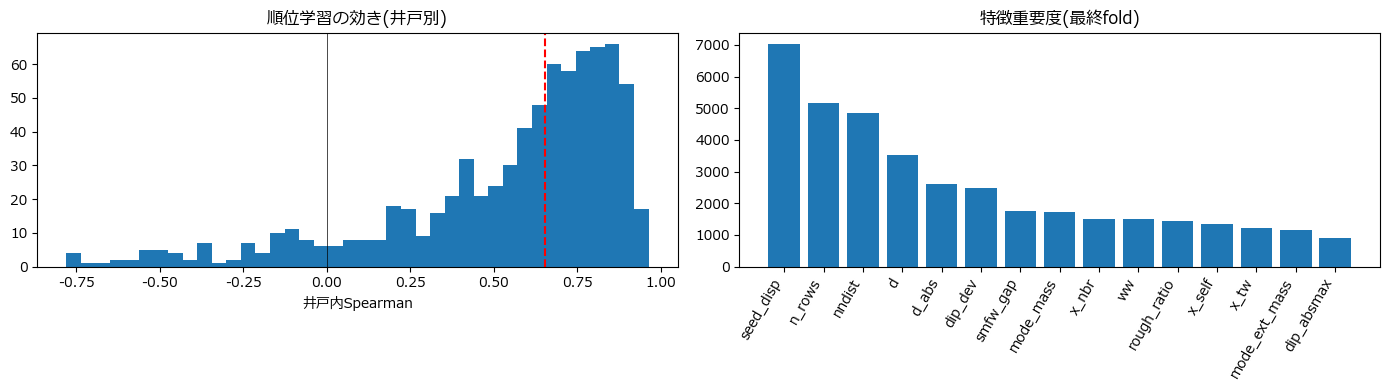

In [3]:
# ===== 学習: LightGBM回帰(目的=井戸内z誤差) GroupKFold(5) → OOF q̂ =====
from sklearn.model_selection import GroupKFold
from scipy.stats import spearmanr
import lightgbm as lgb

FEATS = ["src_tw", "src_self", "src_nbr", "pset", "flt_sm", "ww", "ww_rank", "ll_z",
         "d", "d_abs", "mode_mass", "mode_is_top", "mode_ext_mass",
         "x_tw", "x_self", "x_nbr", "dip_dev", "dip_absmax", "geo_jump", "rough_ratio",
         "smfw_gap", "seed_disp", "nbr_ok", "nndist", "nrefs", "n_rows", "md_len"]
X = np.nan_to_num(TT[FEATS].to_numpy(np.float32), nan=-999.0)
yz = TT["y"].to_numpy(np.float32); grp = TT["well"].to_numpy()
q_oof = np.zeros(len(TT), np.float32)
for tr, va in GroupKFold(5).split(X, yz, grp):
    mdl = lgb.LGBMRegressor(n_estimators=700, learning_rate=0.05, num_leaves=63,
                            min_child_samples=100, subsample=0.8, subsample_freq=1,
                            colsample_bytree=0.8, reg_lambda=1.0, verbose=-1)
    mdl.fit(X[tr], yz[tr])
    q_oof[va] = mdl.predict(X[va])
TT["q_oof"] = q_oof
sp = []
for w, sub in TT.groupby("well"):
    if len(sub) > 10 and sub["y"].std() > 1e-6:
        sp.append(spearmanr(sub["q_oof"], sub["y"]).statistic)
sp = np.array(sp)
print(f"井戸内 Spearman(q̂ vs 実誤差): median {np.median(sp):.3f} / mean {np.mean(sp):.3f}"
      f" / 正 {np.mean(sp > 0):.0%}(0.3超なら順位はかなり学べている)")
imp = pd.Series(mdl.feature_importances_, index=FEATS).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(sp, bins=40); ax[0].axvline(0, c="k", lw=0.5); ax[0].axvline(np.median(sp), c="r", ls="--")
ax[0].set_xlabel("井戸内Spearman"); ax[0].set_title("順位学習の効き(井戸別)")
ax[1].bar(imp.index[:15], imp.values[:15]); plt.sca(ax[1]); plt.xticks(rotation=60, ha="right")
ax[1].set_title("特徴重要度(最終fold)"); plt.tight_layout(); plt.show()
TT.to_parquet(ART / "traj_table.parquet", index=False)   # q_oof 込みで上書き(v35還流用)


基準: 等重みコンセンサス 8.1744 / oracle(1本) 4.1472
         rule  overall
 softmax β0.5 7.945223
 softmax β1.0 7.946802
 softmax β2.0 7.981059
softmax β0.25 7.986379
 softmax β4.0 8.023306
   top-128 平均 8.035249
    top-64 平均 8.131762
    top-16 平均 8.443582
     top-4 平均 8.653058
     top-1 平均 9.229914


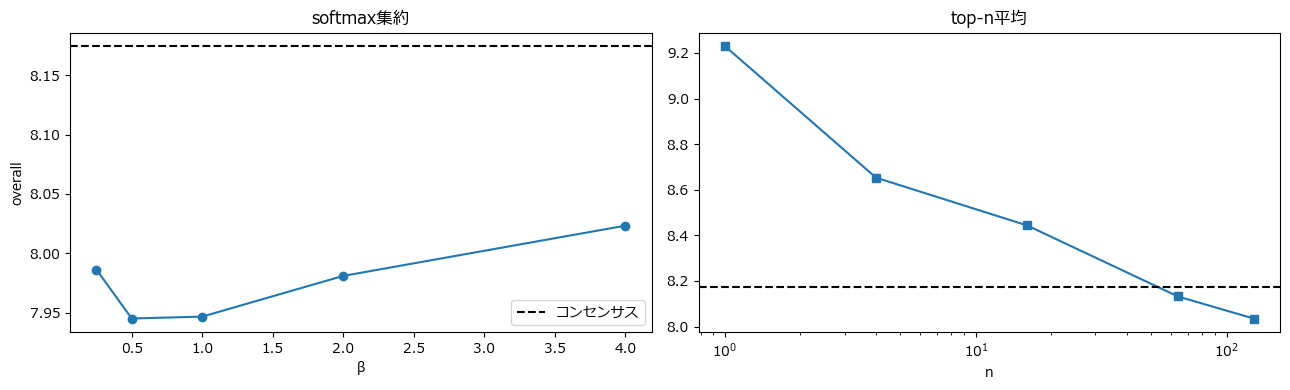

In [4]:
# ===== 集約ゲート: softmax(−q̂·β)/top-n 加重平均軌跡 vs コンセンサス・ww平均・oracle =====
Q = {w: sub for w, sub in TT.groupby("well")}
def agg_eval(mode, param):
    e_all = []
    for w, (ALL, T, err) in TRAJ.items():
        sub = Q.get(w)
        if sub is None or len(sub) != len(ALL):
            # 非有限で落ちた軌跡がある井戸: テーブル行と ALL の対応が崩れるのでスキップ
            continue
        q = sub["q_oof"].to_numpy()
        if mode == "softmax":
            wgt = np.exp(-param * q); wgt = wgt / wgt.sum()
        elif mode == "topn":
            k = min(param, len(q)); idx = np.argsort(q)[:k]
            wgt = np.zeros(len(q)); wgt[idx] = 1.0 / k
        est = (wgt[:, None] * ALL).sum(0)
        e_all.append(est - tvt_true[rows_of[w][:T]])
    return rmse(np.concatenate(e_all))
def base_eval(kind):
    e_all = []
    for w, (ALL, T, err) in TRAJ.items():
        if kind == "cons":
            est = np.median(ALL, axis=0)
        elif kind == "oracle1":
            est = ALL[int(np.argmin(err))]
        e_all.append(est - tvt_true[rows_of[w][:T]])
    return rmse(np.concatenate(e_all))
print(f"基準: 等重みコンセンサス {base_eval('cons'):.4f} / oracle(1本) {base_eval('oracle1'):.4f}")
res = []
for b in [0.25, 0.5, 1.0, 2.0, 4.0]:
    res.append((f"softmax β{b}", agg_eval("softmax", b)))
for n in [1, 4, 16, 64, 128]:
    res.append((f"top-{n} 平均", agg_eval("topn", n)))
R = pd.DataFrame(res, columns=["rule", "overall"]).sort_values("overall")
print(R.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sub = [x for x in res if x[0].startswith("softmax")]
ax[0].plot([0.25, 0.5, 1.0, 2.0, 4.0], [x[1] for x in sub], "o-")
ax[0].axhline(base_eval("cons"), c="k", ls="--", label="コンセンサス")
ax[0].set_xlabel("β"); ax[0].set_ylabel("overall"); ax[0].legend(); ax[0].set_title("softmax集約")
sub = [x for x in res if x[0].startswith("top")]
ax[1].plot([1, 4, 16, 64, 128], [x[1] for x in sub], "s-")
ax[1].axhline(base_eval("cons"), c="k", ls="--"); ax[1].set_xscale("log")
ax[1].set_xlabel("n"); ax[1].set_title("top-n平均"); plt.tight_layout(); plt.show()


In [5]:
# ===== 判定と保存 =====
best = R.iloc[0]
cons_ov = base_eval("cons")
verdict = dict(cons=cons_ov, oracle1=base_eval("oracle1"),
               best_rule=str(best["rule"]), best_overall=float(best["overall"]),
               spearman_median=float(np.median(sp)),
               n_rows=int(len(TT)), n_wells=int(TT["well"].nunique()))
(ART / "ranker_results.json").write_text(json.dumps(verdict, indent=1))
print("=" * 70)
print(f"学習ゲート: 井戸内Spearman median {np.median(sp):.3f}")
print(f"集約ゲート: best {best['rule']} = {best['overall']:.4f} vs コンセンサス {cons_ov:.4f}"
      f" → {'PASS(v35特徴に還流へ)' if best['overall'] < cons_ov - 0.05 else 'FAIL(集約は等重みで十分=撤退)'}")
print("保存:", ART / "ranker_results.json", "/ traj_table.parquet(q_oof込み)")


学習ゲート: 井戸内Spearman median 0.654
集約ゲート: best softmax β0.5 = 7.9452 vs コンセンサス 8.1744 → PASS(v35特徴に還流へ)
保存: C:\Users\kosaka256\Documents\rogii_claude\v34\artifacts_v34\ranker_results.json / traj_table.parquet(q_oof込み)
